In [4]:
%load_ext autoreload
%autoreload 2

import numpy as np
import preprocessing as prep
import matplotlib.pyplot as plt
import implementations as impl


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


SyntaxError: invalid syntax (preprocessing.py, line 1)

## Data visualization and Data Processing

In [24]:
from helpers import load_csv_data

#loading dataset
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("data/dataset")

In [25]:
print(train_ids.shape, y_train.shape, x_train.shape, x_test.shape)   
print(np.unique(y_train))

(328135,) (328135,) (328135, 321) (109379, 321)
[-1  1]


## Missing values

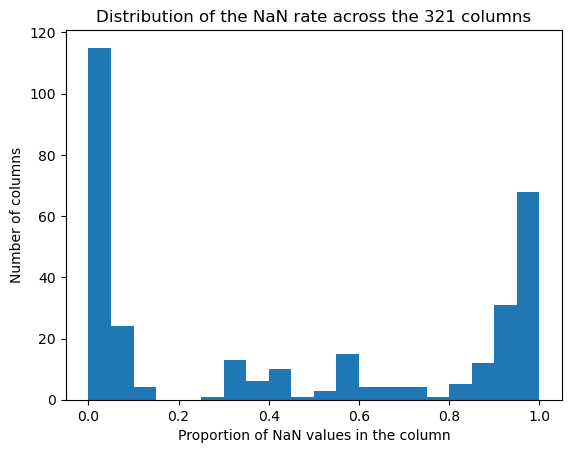

In [27]:
nan_rate = np.isnan(x_train).mean(axis=0)

plt.hist(nan_rate, bins=20)
plt.xlabel("Proportion of NaN values in the column")
plt.ylabel("Number of columns")
plt.title("Distribution of the NaN rate across the 321 columns")
plt.show()

In [34]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("data/dataset")
names = prep.load_feature_names("data/dataset/x_train.csv")

# 1. Split
x_tr, x_va, y_tr, y_va = prep.split_data(x_train, y_train, ratio=0.8, seed=1)

# 2. Preprocessing (fit sur x_tr seulement)
X_tr, X_va, X_te, feature_names, params = prep.preprocess_split(x_tr, x_va, x_test, names)
tx_tr, tx_va, tx_te = prep.add_bias(X_tr, X_va, X_te)

# 3. Entraînement : la régression logistique attend des labels 0/1
y_tr01 = (y_tr == 1).astype(float)
w, loss = impl.reg_logistic_regression(y_tr01, tx_tr, lambda_=1e-4,
                                  initial_w=np.zeros(tx_tr.shape[1]),
                                  max_iters=500, gamma=0.5)